# Sales Performance Dashboard (Retail Analytics)
**Tools:** SQL (SQLite), Python (Pandas, NumPy, SciPy, Matplotlib, Plotly), Excel, Power BI

**What this project does:** It builds a retail sales dataset (2023-2025), queries it with SQL,
finds revenue trends with Python, checks the findings with descriptive and inferential statistics,
estimates how much extra revenue the underperforming regions could bring, and exports files
for Excel and Power BI.

**Note:** The data is synthetic (generated by code with a fixed random seed), so the numbers
are reproducible but they are not real company numbers. Say this openly if asked.

## 0. Setup

In [1]:
import os
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
plt.rcParams["figure.figsize"] = (9, 4.5)
OUT = "outputs"
os.makedirs(OUT, exist_ok=True)
rng = np.random.default_rng(42)  # fixed seed = same results every run

## 1. Create the dataset (no download needed)
Each row is one order line. Regions differ in how many orders they receive (a region
weight), months have seasonality (Nov/Dec are busy), and sales grow a little each year.

In [2]:
N = 15000
regions = ["North", "South", "East", "West", "Central"]
region_weight = np.array([1.00, 1.20, 0.80, 1.10, 0.70])
region_weight = region_weight / region_weight.sum()

catalog = {
    "Technology":      {"products": ["Laptop", "Phone", "Tablet", "Monitor", "Headphones"],
                        "price": (150, 900), "margin": 0.18},
    "Furniture":       {"products": ["Chair", "Desk", "Bookcase", "Sofa", "Cabinet"],
                        "price": (80, 600), "margin": 0.10},
    "Office Supplies": {"products": ["Paper", "Binder", "Pens", "Stapler", "Labels"],
                        "price": (3, 60), "margin": 0.25},
}
segments = ["Consumer", "Corporate", "Home Office"]
season = {1: .8, 2: .8, 3: .9, 4: .95, 5: 1.0, 6: 1.0,
          7: .95, 8: 1.0, 9: 1.05, 10: 1.1, 11: 1.4, 12: 1.5}
year_growth = {2023: 1.0, 2024: 1.08, 2025: 1.15}

# order dates: sample days, weighted by year growth and month seasonality
days = pd.date_range("2023-01-01", "2025-12-31")
day_w = np.array([season[d.month] * year_growth[d.year] for d in days])
day_w = day_w / day_w.sum()
order_dates = rng.choice(days, size=N, p=day_w)

rows = []
cat_names = list(catalog.keys())
cat_probs = [0.25, 0.20, 0.55]
for i in range(N):
    cat = rng.choice(cat_names, p=cat_probs)
    info = catalog[cat]
    lo, hi = info["price"]
    unit_price = round(rng.uniform(lo, hi), 2)
    qty = int(rng.integers(1, 8))
    discount = float(rng.choice([0, 0.05, 0.10, 0.20, 0.30], p=[.45, .2, .15, .12, .08]))
    sales = qty * unit_price * (1 - discount)
    # profit falls as discount rises; a little random noise
    profit = sales * (info["margin"] - 0.9 * discount + rng.normal(0, 0.03))
    rows.append({
        "order_id": f"ORD-{100000 + i}",
        "order_date": order_dates[i],
        "region": rng.choice(regions, p=region_weight),
        "category": cat,
        "product": rng.choice(info["products"]),
        "segment": rng.choice(segments, p=[.55, .30, .15]),
        "quantity": qty,
        "unit_price": unit_price,
        "discount": discount,
        "sales": round(sales, 2),
        "profit": round(profit, 2),
    })

df = pd.DataFrame(rows)
df["order_date"] = pd.to_datetime(df["order_date"])
print(df.shape)
df.head()

(15000, 11)


,order_id,order_date,region,category,product,segment,quantity,unit_price,discount,sales,profit
0,ORD-100000,2025-06-04,North,Furniture,Desk,Consumer,1,133.46,0.20,106.77,-2.86
1,ORD-100001,2024-06-12,West,Office Supplies,Pens,Corporate,3,27.62,0.00,82.86,21.99
2,ORD-100002,2025-09-04,South,Furniture,Desk,Home Office,6,544.70,0.20,"2,614.56",-229.51
3,ORD-100003,2025-03-11,South,Office Supplies,Stapler,Consumer,2,46.12,0.20,73.79,9.46
4,ORD-100004,2023-05-12,South,Office Supplies,Labels,Corporate,3,36.50,0.05,104.02,18.23


## 2. Data cleaning and quick checks

In [3]:
print("Missing values:\n", df.isna().sum(), "\n")
print("Duplicate order ids:", df["order_id"].duplicated().sum())
df = df.drop_duplicates("order_id")
df = df[(df["sales"] > 0) & (df["quantity"] > 0)]

df["year"] = df["order_date"].dt.year
df["month"] = df["order_date"].dt.month
df["year_month"] = df["order_date"].dt.to_period("M").astype(str)
df["profit_margin"] = df["profit"] / df["sales"]
print("Clean rows:", len(df))

Missing values:
 order_id      0
order_date    0
region        0
category      0
product       0
segment       0
quantity      0
unit_price    0
discount      0
sales         0
profit        0
dtype: int64 

Duplicate order ids: 0
Clean rows: 15000


## 3. SQL analysis (SQLite, runs inside Python)

In [4]:
conn = sqlite3.connect(":memory:")
df_sql = df.copy()
df_sql["order_date"] = df_sql["order_date"].dt.strftime("%Y-%m-%d")
df_sql.to_sql("sales", conn, index=False, if_exists="replace")

def q(sql):
    return pd.read_sql_query(sql, conn)

# 3.1 Revenue, profit and orders by region
region_sql = q("""
SELECT region,
       ROUND(SUM(sales), 2)  AS revenue,
       ROUND(SUM(profit), 2) AS profit,
       COUNT(*)              AS orders,
       ROUND(AVG(sales), 2)  AS avg_order_value
FROM sales
GROUP BY region
ORDER BY revenue DESC
""")
print(region_sql)

    region      revenue     profit  orders  avg_order_value
0    South 2,964,042.91 306,974.79    3755           789.36
1     West 2,821,142.09 290,568.66    3411           827.07
2    North 2,585,124.66 256,741.51    3133           825.13
3     East 2,033,717.75 206,668.32    2527           804.80
4  Central 1,758,144.22 177,869.60    2174           808.71


In [5]:
# 3.2 Revenue by year and region, with year-over-year growth (window function)
yoy_sql = q("""
WITH yr AS (
    SELECT region, year, SUM(sales) AS revenue
    FROM sales GROUP BY region, year
)
SELECT region, year, ROUND(revenue, 2) AS revenue,
       ROUND(100.0 * (revenue - LAG(revenue) OVER (PARTITION BY region ORDER BY year))
             / LAG(revenue) OVER (PARTITION BY region ORDER BY year), 2) AS yoy_growth_pct
FROM yr
ORDER BY region, year
""")
print(yoy_sql)

     region  year      revenue  yoy_growth_pct
0   Central  2023   514,448.68             NaN
1   Central  2024   610,881.30           18.74
2   Central  2025   632,814.24            3.59
3      East  2023   637,588.19             NaN
4      East  2024   631,242.40           -1.00
5      East  2025   764,887.16           21.17
6     North  2023   802,853.00             NaN
7     North  2024   866,509.12            7.93
8     North  2025   915,762.54            5.68
9     South  2023   948,313.38             NaN
10    South  2024 1,017,141.72            7.26
11    South  2025   998,587.81           -1.82
12     West  2023   889,767.49             NaN
13     West  2024   961,963.66            8.11
14     West  2025   969,410.94            0.77


In [6]:
# 3.3 Category performance
category_sql = q("""
SELECT category,
       ROUND(SUM(sales), 2) AS revenue,
       ROUND(SUM(profit), 2) AS profit,
       ROUND(100.0 * SUM(profit) / SUM(sales), 2) AS margin_pct
FROM sales GROUP BY category ORDER BY revenue DESC
""")
print(category_sql)

          category      revenue     profit  margin_pct
0       Technology 7,343,331.34 893,852.84       12.17
1        Furniture 3,858,769.63 160,736.56        4.17
2  Office Supplies   960,070.66 184,233.48       19.19


In [7]:
# 3.4 Top 5 and bottom 5 products by revenue
prod_sql = q("""
SELECT category, product, ROUND(SUM(sales), 2) AS revenue
FROM sales GROUP BY category, product ORDER BY revenue DESC
""")
print("Top 5:\n", prod_sql.head(5), "\n\nBottom 5:\n", prod_sql.tail(5))

Top 5:
      category     product      revenue
0  Technology     Monitor 1,501,478.93
1  Technology      Laptop 1,497,380.04
2  Technology       Phone 1,481,237.46
3  Technology      Tablet 1,456,811.93
4  Technology  Headphones 1,406,422.98 

Bottom 5:
            category  product    revenue
10  Office Supplies   Binder 198,958.13
11  Office Supplies    Paper 198,151.49
12  Office Supplies     Pens 190,960.23
13  Office Supplies   Labels 187,531.45
14  Office Supplies  Stapler 184,469.36


## 4. Python: revenue trends

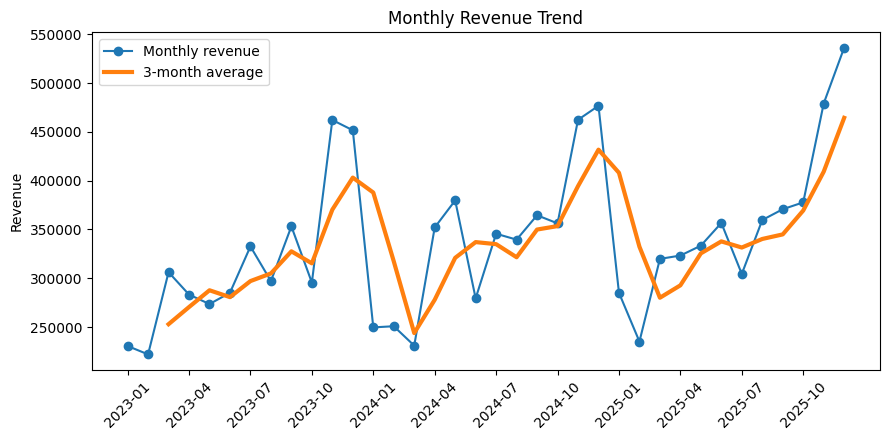

Yearly revenue:
 year
2023   3,792,970.74
2024   4,087,738.20
2025   4,281,462.69
Name: sales, dtype: float64

YoY growth %:
 year
2023    NaN
2024   7.77
2025   4.74
Name: sales, dtype: float64


In [8]:
monthly = df.groupby("year_month", as_index=False)["sales"].sum()
monthly["mom_growth_pct"] = monthly["sales"].pct_change() * 100
monthly["rolling_3m"] = monthly["sales"].rolling(3).mean()

fig, ax = plt.subplots()
ax.plot(monthly["year_month"], monthly["sales"], marker="o", label="Monthly revenue")
ax.plot(monthly["year_month"], monthly["rolling_3m"], linewidth=3, label="3-month average")
ax.set_xticks(range(0, len(monthly), 3))
ax.set_xticklabels(monthly["year_month"][::3], rotation=45)
ax.set_title("Monthly Revenue Trend")
ax.set_ylabel("Revenue")
ax.legend()
plt.tight_layout()
plt.savefig(f"{OUT}/monthly_trend.png", dpi=150)
plt.show()

yearly = df.groupby("year")["sales"].sum()
print("Yearly revenue:\n", yearly)
print("\nYoY growth %:\n", (yearly.pct_change() * 100).round(2))

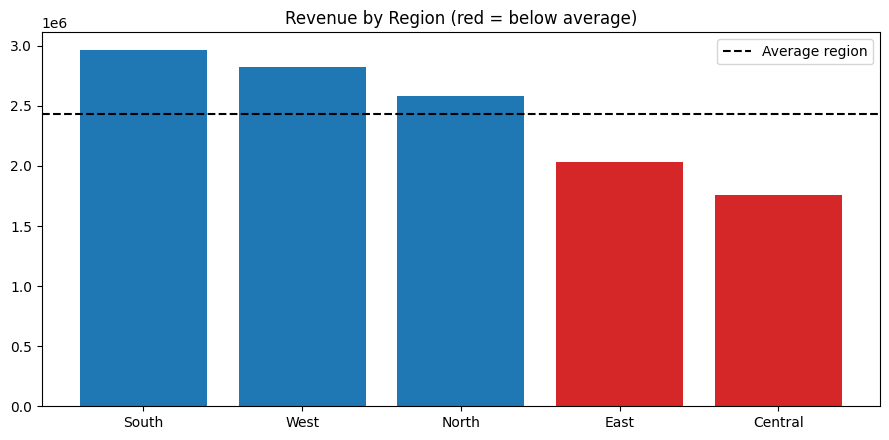

In [9]:
region_rev = df.groupby("region")["sales"].sum().sort_values(ascending=False)
fig, ax = plt.subplots()
colors = ["tab:red" if v < region_rev.mean() else "tab:blue" for v in region_rev]
ax.bar(region_rev.index, region_rev.values, color=colors)
ax.axhline(region_rev.mean(), color="black", linestyle="--", label="Average region")
ax.set_title("Revenue by Region (red = below average)")
ax.legend()
plt.tight_layout()
plt.savefig(f"{OUT}/region_revenue.png", dpi=150)
plt.show()

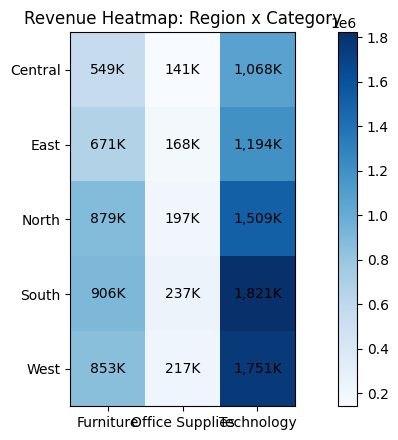

In [10]:
heat = df.pivot_table(index="region", columns="category", values="sales", aggfunc="sum")
fig, ax = plt.subplots()
im = ax.imshow(heat.values, cmap="Blues")
ax.set_xticks(range(len(heat.columns)), heat.columns)
ax.set_yticks(range(len(heat.index)), heat.index)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        ax.text(j, i, f"{heat.values[i, j]/1000:,.0f}K", ha="center", va="center")
ax.set_title("Revenue Heatmap: Region x Category")
plt.colorbar(im)
plt.tight_layout()
plt.savefig(f"{OUT}/region_category_heatmap.png", dpi=150)
plt.show()

## 5. Descriptive statistics

In [11]:
desc = df[["sales", "profit", "quantity", "discount"]].describe().T
desc["median"] = df[["sales", "profit", "quantity", "discount"]].median()
desc["skew"] = df[["sales", "profit", "quantity", "discount"]].skew()
print(desc[["mean", "median", "std", "min", "max", "skew"]])

by_region_stats = df.groupby("region")["sales"].agg(["mean", "median", "std", "count"])
print("\nOrder value by region:\n", by_region_stats)

           mean  median      std     min      max  skew
sales    810.81  236.64 1,132.86    2.30 6,288.17  1.91
profit    82.59   26.46   175.47 -645.59 1,433.76  2.62
quantity   3.99    4.00     2.00    1.00     7.00  0.01
discount   0.07    0.05     0.09    0.00     0.30  1.24

Order value by region:
           mean  median      std  count
region                                
Central 808.71  227.30 1,125.38   2174
East    804.80  234.60 1,144.89   2527
North   825.13  243.46 1,148.24   3133
South   789.36  227.93 1,105.75   3755
West    827.07  248.62 1,144.08   3411


## 6. Inferential statistics (are the differences real or just chance?)

ANOVA (order value across regions): F = 0.66, p = 0.6219
Correlation discount vs profit margin: r = -0.786, p = 0
t-test margin (discount>=20% vs <20%): t = -118.12, p = 0
Mean margin: high discount -1.42%, low discount 17.33%


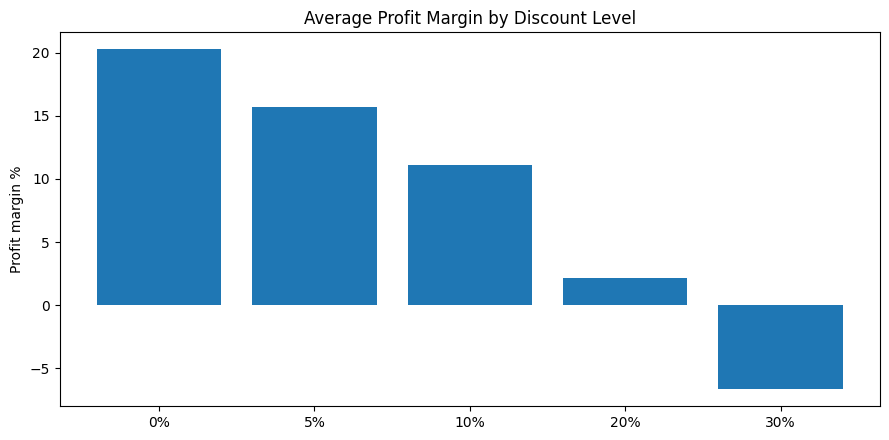

In [12]:
# 6.1 ANOVA: do regions differ in average order value?
groups = [g["sales"].values for _, g in df.groupby("region")]
f_stat, p_anova = stats.f_oneway(*groups)
print(f"ANOVA (order value across regions): F = {f_stat:.2f}, p = {p_anova:.4f}")

# 6.2 Correlation: discount vs profit margin
r, p_corr = stats.pearsonr(df["discount"], df["profit_margin"])
print(f"Correlation discount vs profit margin: r = {r:.3f}, p = {p_corr:.4g}")

# 6.3 t-test: high-discount orders (>=20%) vs low-discount orders in profit margin
hi = df.loc[df["discount"] >= 0.20, "profit_margin"]
lo = df.loc[df["discount"] < 0.20, "profit_margin"]
t_stat, p_t = stats.ttest_ind(hi, lo, equal_var=False)
print(f"t-test margin (discount>=20% vs <20%): t = {t_stat:.2f}, p = {p_t:.4g}")
print(f"Mean margin: high discount {hi.mean():.2%}, low discount {lo.mean():.2%}")

fig, ax = plt.subplots()
disc_margin = df.groupby("discount")["profit_margin"].mean() * 100
ax.bar([f"{int(d*100)}%" for d in disc_margin.index], disc_margin.values)
ax.set_title("Average Profit Margin by Discount Level")
ax.set_ylabel("Profit margin %")
plt.tight_layout()
plt.savefig(f"{OUT}/discount_vs_margin.png", dpi=150)
plt.show()

## 7. Revenue growth opportunity in underperforming regions
**Method (simple and explainable):**
1. Find the average revenue per region.
2. Regions below that average are "underperforming".
3. Opportunity = extra revenue if each underperforming region reached the average,
   shown as a percentage of current total revenue.

The result is whatever the data produces. We also show a more cautious scenario
where an underperforming region only closes part of its gap.

In [13]:
rev = df.groupby("region")["sales"].sum()
avg_region = rev.mean()
under = rev[rev < avg_region]
gap = (avg_region - under)

opp = pd.DataFrame({
    "current_revenue": under,
    "average_region_revenue": avg_region,
    "gap_to_average": gap,
    "gap_pct_of_region": gap / under * 100,
})
print(opp)

total = rev.sum()
for closure in [1.0, 0.5, 0.25]:
    extra = gap.sum() * closure
    print(f"If gap is closed by {closure:>4.0%}: extra revenue = {extra:,.0f} "
          f"= {extra / total:.2%} of current total revenue")

full_opportunity_pct = gap.sum() / total * 100
print(f"\nHEADLINE (full gap): {full_opportunity_pct:.1f}% revenue growth opportunity")

         current_revenue  average_region_revenue  gap_to_average  \
region                                                             
Central     1,758,144.22            2,432,434.33      674,290.11   
East        2,033,717.75            2,432,434.33      398,716.58   

         gap_pct_of_region  
region                      
Central              38.35  
East                 19.61  
If gap is closed by 100%: extra revenue = 1,073,007 = 8.82% of current total revenue
If gap is closed by  50%: extra revenue = 536,503 = 4.41% of current total revenue
If gap is closed by  25%: extra revenue = 268,252 = 2.21% of current total revenue

HEADLINE (full gap): 8.8% revenue growth opportunity


## 8. Where is each underperforming region weak? (to suggest strategies)

In [14]:
mix = df.pivot_table(index="region", columns="category", values="sales", aggfunc="sum")
mix_share = mix.div(mix.sum(axis=1), axis=0) * 100
print("Category share of revenue (%) by region:\n", mix_share.round(1))

seg = df.pivot_table(index="region", columns="segment", values="sales", aggfunc="sum")
print("\nRevenue by customer segment:\n", seg)

aov = df.groupby("region")["sales"].mean()
orders = df.groupby("region")["order_id"].count()
print("\nAverage order value:\n", aov.round(2))
print("\nNumber of orders:\n", orders)
print("\nReading: if AOV is similar across regions but order count is low,")
print("the lever is more customers/orders (marketing, distribution), not higher prices.")

Category share of revenue (%) by region:
 category  Furniture  Office Supplies  Technology
region                                          
Central       31.20             8.00       60.70
East          33.00             8.30       58.70
North         34.00             7.60       58.40
South         30.60             8.00       61.40
West          30.20             7.70       62.10

Revenue by customer segment:
 segment     Consumer  Corporate  Home Office
region                                      
Central   975,589.45 523,090.12   259,464.65
East    1,085,843.70 643,777.52   304,096.53
North   1,433,641.49 791,728.15   359,755.02
South   1,608,083.74 870,751.88   485,207.29
West    1,602,812.06 802,792.51   415,537.52

Average order value:
 region
Central   808.71
East      804.80
North     825.13
South     789.36
West      827.07
Name: sales, dtype: float64

Number of orders:
 region
Central    2174
East       2527
North      3133
South      3755
West       3411
Name: order_id, dty

## 9. Interactive dashboard with filters (this is the UI)
Run the cell below. You get KPI cards, charts, and filter boxes (Region, Year, Category).
Click in a filter box to select options (hold Ctrl / Cmd to select several) and the
whole dashboard updates. Works in Google Colab and in VS Code notebooks (.ipynb).

In [15]:
import subprocess, sys
try:
    import plotly, ipywidgets
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "plotly", "ipywidgets"])

import plotly.graph_objects as go
from plotly.subplots import make_subplots
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output

all_regions = sorted(df["region"].unique())
all_years = sorted(df["year"].unique())
all_cats = sorted(df["category"].unique())

w_region = widgets.SelectMultiple(options=all_regions, value=tuple(all_regions),
                                  description="Region", rows=5,
                                  layout=widgets.Layout(width="230px"))
w_year = widgets.SelectMultiple(options=[int(y) for y in all_years],
                                value=tuple(int(y) for y in all_years),
                                description="Year", rows=3,
                                layout=widgets.Layout(width="230px"))
w_cat = widgets.SelectMultiple(options=all_cats, value=tuple(all_cats),
                               description="Category", rows=3,
                               layout=widgets.Layout(width="260px"))
dash_out = widgets.Output()

def kpi_card(title, value):
    return (f"<div style='flex:1;min-width:150px;padding:14px;margin:4px;border-radius:10px;"
            f"background:#f1f5f9;border:1px solid #cbd5e1;text-align:center;color:#0f172a'>"
            f"<div style='font-size:12px;color:#475569'>{title}</div>"
            f"<div style='font-size:22px;font-weight:700'>{value}</div></div>")

def draw_dashboard(_=None):
    with dash_out:
        clear_output(wait=True)
        d = df[df["region"].isin(w_region.value)
               & df["year"].isin(w_year.value)
               & df["category"].isin(w_cat.value)]
        if d.empty:
            print("No data for this selection. Pick at least one option in each filter.")
            return

        total_sales = d["sales"].sum()
        total_profit = d["profit"].sum()
        margin = total_profit / total_sales * 100
        yearly_d = d.groupby("year")["sales"].sum()
        yoy = f"{yearly_d.pct_change().iloc[-1] * 100:.1f}%" if len(yearly_d) > 1 else "n/a"
        cards = "".join([
            kpi_card("Total Sales", f"{total_sales:,.0f}"),
            kpi_card("Total Profit", f"{total_profit:,.0f}"),
            kpi_card("Profit Margin", f"{margin:.1f}%"),
            kpi_card("Orders", f"{len(d):,}"),
            kpi_card("Avg Order Value", f"{d['sales'].mean():,.0f}"),
            kpi_card("Latest YoY Growth", yoy),
        ])
        display(HTML(f"<div style='display:flex;flex-wrap:wrap'>{cards}</div>"))

        m = d.groupby("year_month")["sales"].sum().reset_index()
        r = d.groupby("region")["sales"].sum().sort_values(ascending=False)
        c = d.groupby("category")["sales"].sum()
        dm = d.groupby("discount")["profit_margin"].mean() * 100
        avg_r = r.mean()

        fig = make_subplots(
            rows=2, cols=2,
            subplot_titles=("Monthly Revenue", "Revenue by Region (red = below average)",
                            "Revenue by Category", "Profit Margin by Discount Level"),
            specs=[[{"type": "xy"}, {"type": "xy"}], [{"type": "domain"}, {"type": "xy"}]],
        )
        fig.add_trace(go.Scatter(x=m["year_month"], y=m["sales"], mode="lines+markers",
                                 name="Revenue"), 1, 1)
        fig.add_trace(go.Bar(x=r.index, y=r.values, name="Revenue",
                             marker_color=["#dc2626" if v < avg_r else "#2563eb" for v in r.values]), 1, 2)
        fig.add_trace(go.Pie(labels=c.index, values=c.values, hole=0.45), 2, 1)
        fig.add_trace(go.Bar(x=[f"{int(x * 100)}%" for x in dm.index], y=dm.values,
                             name="Margin %"), 2, 2)
        fig.update_layout(height=720, showlegend=False, margin=dict(t=60, b=20))
        fig.show()

for w in (w_region, w_year, w_cat):
    w.observe(draw_dashboard, names="value")

display(HTML("<h2 style='margin:6px 0'>Sales Performance Dashboard</h2>"
             "<div style='color:#475569'>Ctrl/Cmd + click to select several options in a filter.</div>"))
display(widgets.HBox([w_region, w_year, w_cat]))
display(dash_out)
draw_dashboard()

Output()

In [16]:
# Also save a standalone version (full data, no filters) that you can open in any browser.
fig_static = make_subplots(
    rows=2, cols=2,
    subplot_titles=("Monthly Revenue", "Revenue by Region", "Revenue by Category",
                    "Profit Margin by Discount"),
    specs=[[{"type": "xy"}, {"type": "xy"}], [{"type": "domain"}, {"type": "xy"}]],
)
fig_static.add_trace(go.Scatter(x=monthly["year_month"], y=monthly["sales"], mode="lines+markers"), 1, 1)
fig_static.add_trace(go.Bar(x=region_rev.index, y=region_rev.values), 1, 2)
cat_rev = df.groupby("category")["sales"].sum()
fig_static.add_trace(go.Pie(labels=cat_rev.index, values=cat_rev.values, hole=0.4), 2, 1)
fig_static.add_trace(go.Bar(x=[f"{int(x*100)}%" for x in disc_margin.index], y=disc_margin.values), 2, 2)
fig_static.update_layout(height=750, title_text="Sales Performance Dashboard", showlegend=False)
fig_static.write_html(f"{OUT}/sales_dashboard.html")
print("Saved outputs/sales_dashboard.html (download it from the Files panel and open in a browser)")

Saved outputs/sales_dashboard.html (download it from the Files panel and open in a browser)


## 10. Excel validation and Power BI export

In [17]:
# Excel workbook with pivot-style summary sheets, to cross-check the SQL/Python numbers.
# (Pandas builds the pivot tables; you can also insert real Excel PivotTables
#  from the 'data' sheet to validate: Insert > PivotTable.)
excel_path = f"{OUT}/sales_analysis.xlsx"
with pd.ExcelWriter(excel_path) as xw:
    df.to_excel(xw, sheet_name="data", index=False)
    df.pivot_table(index="region", columns="year", values="sales", aggfunc="sum",
                   margins=True).to_excel(xw, sheet_name="pivot_region_year")
    df.pivot_table(index="category", columns="region", values="sales", aggfunc="sum",
                   margins=True).to_excel(xw, sheet_name="pivot_category_region")
    opp.to_excel(xw, sheet_name="opportunity")

# Cross-check: SQL total must equal Pandas total
sql_total = q("SELECT SUM(sales) AS t FROM sales")["t"][0]
print(f"SQL total = {sql_total:,.2f} | Pandas total = {df['sales'].sum():,.2f} | "
      f"match = {np.isclose(sql_total, df['sales'].sum())}")

# CSV for Power BI
df.drop(columns=["year_month"]).assign(order_date=df["order_date"].dt.date).to_csv(
    f"{OUT}/sales_for_powerbi.csv", index=False)

dax = """
-- Power BI: Home > Get Data > Text/CSV > sales_for_powerbi.csv > Load
-- Then Modeling > New measure, and paste each measure below.

Total Sales = SUM(sales[sales])
Total Profit = SUM(sales[profit])
Profit Margin % = DIVIDE([Total Profit], [Total Sales])
Orders = DISTINCTCOUNT(sales[order_id])
Avg Order Value = DIVIDE([Total Sales], [Orders])

Sales LY = CALCULATE([Total Sales], SAMEPERIODLASTYEAR('Date'[Date]))
YoY Growth % = DIVIDE([Total Sales] - [Sales LY], [Sales LY])

Avg Region Sales =
AVERAGEX(ALL(sales[region]), CALCULATE([Total Sales]))

Gap To Avg Region =
VAR gap = [Avg Region Sales] - [Total Sales]
RETURN IF(gap > 0, gap, 0)

-- Date table (Modeling > New table), then mark as date table and relate to sales[order_date]:
Date = CALENDAR(DATE(2023,1,1), DATE(2025,12,31))

-- Suggested dashboard layout:
--  Cards: Total Sales, Total Profit, Profit Margin %, YoY Growth %
--  Line chart: Total Sales by Date[Month]
--  Bar chart: Total Sales by region (conditional colour: Gap To Avg Region > 0 = red)
--  Matrix: region x category with Total Sales
--  Slicers: year, category, segment
"""
with open(f"{OUT}/powerbi_dax_measures.txt", "w") as f:
    f.write(dax)

print("Files in outputs/:", sorted(os.listdir(OUT)))

SQL total = 12,162,171.63 | Pandas total = 12,162,171.63 | match = True
Files in outputs/: ['discount_vs_margin.png', 'monthly_trend.png', 'powerbi_dax_measures.txt', 'region_category_heatmap.png', 'region_revenue.png', 'sales_analysis.xlsx', 'sales_dashboard.html', 'sales_for_powerbi.csv']


## 11. Findings summary (auto-generated from the results above)

In [18]:
best = rev.idxmax()
worst = rev.idxmin()
print(f"""
SUMMARY
- Total revenue: {total:,.0f} across {len(df):,} orders (2023-2025).
- Yearly growth: {', '.join(f'{y}: {g:.1f}%' for y, g in (yearly.pct_change()*100).dropna().items())}.
- Strongest region: {best} ({rev[best]:,.0f}); weakest region: {worst} ({rev[worst]:,.0f}).
- Underperforming regions (below the average region): {', '.join(under.index)}.
- Closing their gap to the average region = {full_opportunity_pct:.1f}% of current revenue
  (a cautious 50% closure = {full_opportunity_pct/2:.1f}%).
- Discounts of 20%+ cut profit margin sharply (see section 6), so growth in weak regions
  should come from more orders/customers, not deeper discounts.
""")


SUMMARY
- Total revenue: 12,162,172 across 15,000 orders (2023-2025).
- Yearly growth: 2024: 7.8%, 2025: 4.7%.
- Strongest region: South (2,964,043); weakest region: Central (1,758,144).
- Underperforming regions (below the average region): Central, East.
- Closing their gap to the average region = 8.8% of current revenue
  (a cautious 50% closure = 4.4%).
- Discounts of 20%+ cut profit margin sharply (see section 6), so growth in weak regions
  should come from more orders/customers, not deeper discounts.

